In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

PROCESSED_DIR = Path("../data/processed")

returns_df = pd.read_parquet(
    PROCESSED_DIR / "daily_returns.parquet"
)

adj_close_df = pd.read_parquet(
    PROCESSED_DIR / "adjusted_close.parquet"
)

adj_ohlc_df = {
    path.stem.replace("_adjusted_ohlc", ""): pd.read_parquet(path)
    for path in PROCESSED_DIR.glob("*_adjusted_ohlc.parquet")
}

print("Returns:", returns_df.shape)
print("Adjusted close:", adj_close_df.shape)
print("Adjusted OHLC instruments:", len(adj_ohlc_df))
print("Sample:", returns_df.index.min(), "to", returns_df.index.max())

Returns: (4959, 15)
Adjusted close: (4959, 15)
Adjusted OHLC instruments: 15
Sample: 2007-03-02 00:00:00 to 2026-11-13 00:00:00


In [2]:
# 1. EWMA volatility estimation

COM = 60
TRADING_DAYS = 252

ewma_vol = returns_df.ewm(
    com=COM,
    min_periods=COM,
    adjust=False
).std()

ewma_vol_annual = ewma_vol * np.sqrt(TRADING_DAYS)

display(ewma_vol_annual.tail())

,SPY,QQQ,IWM,EWJ,VGK,TLT,IEF,SHY,GLD,SLV,DBC,USO,UUP,FXE,FXY
Date,,,,,,,,,,,,,,,
2026-11-09,0.156645,0.254535,0.192268,0.232029,0.167127,0.102183,0.055344,0.015277,0.255271,0.465954,0.209444,0.494877,0.052778,0.051724,0.079067
2026-11-10,0.155547,0.252765,0.191205,0.231325,0.165975,0.104872,0.057651,0.016672,0.258788,0.466777,0.208243,0.491200,0.053675,0.052239,0.079219
2026-11-11,0.156535,0.255225,0.190491,0.232824,0.164689,0.104015,0.057196,0.016539,0.257555,0.463104,0.206593,0.487161,0.054798,0.053488,0.079982
2026-11-12,0.155440,0.253200,0.191883,0.231333,0.163866,0.107406,0.058980,0.016975,0.261319,0.463391,0.204940,0.487321,0.054475,0.053236,0.079327
2026-11-13,0.154358,0.252258,0.190408,0.229533,0.162535,0.106824,0.058596,0.016849,0.259237,0.461187,0.203416,0.483414,0.054200,0.053094,0.078808


In [3]:
print("EWMA volatility shape:", ewma_vol_annual.shape)

print("\nLatest annualized volatility (%):")
display((ewma_vol_annual.iloc[-1] * 100).round(2))

EWMA volatility shape: (4959, 15)

Latest annualized volatility (%):


SPY    15.44
QQQ    25.23
IWM    19.04
EWJ    22.95
VGK    16.25
TLT    10.68
IEF     5.86
SHY     1.68
GLD    25.92
SLV    46.12
DBC    20.34
USO    48.34
UUP     5.42
FXE     5.31
FXY     7.88
Name: 2026-11-13 00:00:00, dtype: float64

In [4]:
# 2. Rolling volatility estimation

ROLLING_WINDOW = 21
TRADING_DAYS = 252

rolling_vol = returns_df.rolling(
    window=ROLLING_WINDOW,
    min_periods=ROLLING_WINDOW
).std()

rolling_vol_annual = rolling_vol * np.sqrt(TRADING_DAYS)

display(rolling_vol_annual.tail())

,SPY,QQQ,IWM,EWJ,VGK,TLT,IEF,SHY,GLD,SLV,DBC,USO,UUP,FXE,FXY
Date,,,,,,,,,,,,,,,
2026-11-09,0.214863,0.344519,0.255587,0.274371,0.200242,0.105288,0.057900,0.015806,0.253268,0.459938,0.206697,0.483576,0.052216,0.054430,0.055375
2026-11-10,0.214962,0.344501,0.256494,0.275983,0.200687,0.118594,0.067516,0.020220,0.268654,0.470614,0.200617,0.478286,0.055074,0.055912,0.058298
2026-11-11,0.221026,0.357636,0.257415,0.286680,0.200773,0.118418,0.067787,0.020258,0.270811,0.470849,0.199740,0.474759,0.058038,0.059101,0.063164
2026-11-12,0.218393,0.352648,0.254745,0.283483,0.201789,0.130041,0.074364,0.021745,0.282438,0.438196,0.200779,0.490446,0.057483,0.058352,0.063153
2026-11-13,0.218226,0.354145,0.251147,0.283925,0.196589,0.122129,0.070597,0.021213,0.273043,0.418496,0.200448,0.481003,0.055410,0.055875,0.063632


In [5]:
print("Rolling volatility shape:", rolling_vol_annual.shape)

print("\nLatest annualized volatility (%):")
display((rolling_vol_annual.iloc[-1] * 100).round(2))

Rolling volatility shape: (4959, 15)

Latest annualized volatility (%):


SPY    21.82
QQQ    35.41
IWM    25.11
EWJ    28.39
VGK    19.66
TLT    12.21
IEF     7.06
SHY     2.12
GLD    27.30
SLV    41.85
DBC    20.04
USO    48.10
UUP     5.54
FXE     5.59
FXY     6.36
Name: 2026-11-13 00:00:00, dtype: float64

In [6]:
vol_comparison = pd.DataFrame({
    "EWMA": ewma_vol_annual.iloc[-1] * 100,
    "Rolling_21D": rolling_vol_annual.iloc[-1] * 100
})

vol_comparison["Difference"] = (
    vol_comparison["Rolling_21D"] - vol_comparison["EWMA"]
)

display(vol_comparison.round(2))

,EWMA,Rolling_21D,Difference
SPY,15.44,21.82,6.39
QQQ,25.23,35.41,10.19
IWM,19.04,25.11,6.07
EWJ,22.95,28.39,5.44
VGK,16.25,19.66,3.41
TLT,10.68,12.21,1.53
IEF,5.86,7.06,1.20
SHY,1.68,2.12,0.44
GLD,25.92,27.30,1.38
SLV,46.12,41.85,-4.27


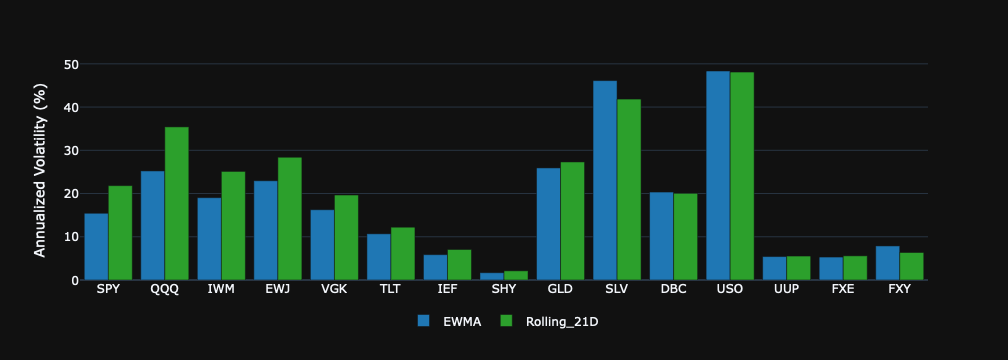

In [9]:
import plotly.express as px

plot_df = vol_comparison.reset_index().melt(
    id_vars='Date' if 'Date' in vol_comparison.columns else 'index',
    value_vars=['EWMA', 'Rolling_21D'],
    var_name='Method',
    value_name='Annualized Volatility (%)'
)
plot_df = plot_df.rename(columns={'index': 'ETF'})

fig = px.bar(
    plot_df,
    x='ETF',
    y='Annualized Volatility (%)',
    color='Method',
    barmode='group',
    color_discrete_map={'EWMA': '#1f77b4', 'Rolling_21D': '#2ca02c'},
    template='plotly_dark'  # Matches your dark theme preference
)
fig.update_layout(
    xaxis_title='',
    yaxis_title='Annualized Volatility (%)',
    legend=dict(
        orientation='h',
        yanchor='bottom',
        y=-0.25,
        xanchor='center',
        x=0.5,
        title=None
    ),
    bargap=0.15
)
fig.show()

In [11]:
# Inspect adjusted OHLC data

ticker = "SPY"

display(adj_ohlc_df[ticker].tail())

print("\nAvailable columns:")
print(adj_ohlc_df[ticker].columns.tolist())

print("\nCheck missing values:")
print(adj_ohlc_df[ticker].isna().sum())

print("raw_data exists:", "raw_data" in globals())

Price,Adj_Open,Adj_High,Adj_Low,Adj_Close
Date,,,,
2026-11-09,741.950012,755.419983,741.030029,752.690002
2026-11-10,747.940002,752.140015,744.859985,749.919983
2026-11-11,756.799988,762.510010,754.900024,759.809998
2026-11-12,753.979980,763.039978,753.669983,757.119995
2026-11-13,760.070007,760.119995,747.880005,754.369995



Available columns:
['Adj_Open', 'Adj_High', 'Adj_Low', 'Adj_Close']

Check missing values:
Price
Adj_Open     0
Adj_High     0
Adj_Low      0
Adj_Close    0
dtype: int64
raw_data exists: False
